In [91]:
%pip install psycopg2-binary

Note: you may need to restart the kernel to use updated packages.


In [92]:
import  pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine

In [93]:
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

url = URL.create(
    drivername="postgresql+psycopg2",
    username="postgres",
    password="Sushant@123",
    host="localhost",
    port=5432,
    database="travel_analytics"
)

engine = create_engine(url)

In [94]:
from sqlalchemy import text

with engine.connect() as connection:
    result = connection.execute(text("SELECT 1;"))
    print(result.fetchone())

(1,)


In [95]:
# Phase 6 Lesson 1 Loading data into pandas

In [96]:
query = """SELECT * FROM analytics.fact_bookings_fx 
                WHERE is_fx_missing = 0; """

bookings = pd.read_sql(query,engine)

In [97]:
bookings.shape

(119877, 27)

In [98]:
# check data types
bookings.info()

<class 'pandas.DataFrame'>
RangeIndex: 119877 entries, 0 to 119876
Data columns (total 27 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   booking_id               119877 non-null  str    
 1   booking_dt               119877 non-null  object 
 2   travel_dt                119877 non-null  object 
 3   agent_id                 119877 non-null  str    
 4   hotel_id                 119877 non-null  str    
 5   supplier_id              119637 non-null  str    
 6   destination_id           119877 non-null  str    
 7   rooms                    119877 non-null  float64
 8   nights                   119877 non-null  float64
 9   booking_status           119877 non-null  str    
 10  payment_status           119877 non-null  str    
 11  currency                 119877 non-null  str    
 12  gross_booking_value      119877 non-null  float64
 13  supplier_cost            119877 non-null  float64
 14  discount_amount

In [99]:
# check missing values
bookings.isnull().sum()

booking_id                   0
booking_dt                   0
travel_dt                    0
agent_id                     0
hotel_id                     0
supplier_id                240
destination_id               0
rooms                        0
nights                       0
booking_status               0
payment_status               0
currency                     0
gross_booking_value          0
supplier_cost                0
discount_amount              0
lead_days                    0
net_revenue                  0
gross_margin_pct             0
is_cancelled                 0
is_supplier_missing          0
fx_month                     0
rate_to_inr                  0
is_fx_missing                0
gross_booking_value_inr      0
supplier_cost_inr            0
discount_amount_inr          0
net_revenue_inr              0
dtype: int64

In [100]:
missing_values = bookings.isnull().sum()
missing_values[missing_values > 0]

supplier_id    240
dtype: int64

In [101]:
#get numerical statistics
bookings.describe()

,rooms,nights,gross_booking_value,supplier_cost,discount_amount,lead_days,net_revenue,gross_margin_pct,is_cancelled,is_supplier_missing,rate_to_inr,is_fx_missing,gross_booking_value_inr,supplier_cost_inr,discount_amount_inr,net_revenue_inr
count,119877.000000,119877.000000,1.198770e+05,1.198770e+05,1.198770e+05,119877.000000,1.198770e+05,119877.000000,119877.000000,119877.000000,119877.000000,119877.0,1.198770e+05,1.198770e+05,119877.000000,1.198770e+05
mean,1.492555,3.858680,1.351935e+06,1.162375e+06,2.117647e+04,27.133453,1.683835e+05,12.420144,0.116444,0.002002,44.962006,0.0,2.181543e+05,1.876215e+05,3412.025911,2.712069e+04
std,0.834471,2.701907,9.356206e+06,8.059714e+06,2.342801e+05,25.499359,1.244498e+06,4.925615,0.320758,0.044700,39.929407,0.0,2.657885e+05,2.290277e+05,7401.892944,3.721335e+04
min,1.000000,1.000000,9.034000e+01,7.103000e+01,0.000000e+00,0.000000,1.550000e+00,1.000000,0.000000,0.000000,0.005300,0.0,5.539880e+03,4.381830e+03,0.000000,1.056888e+02
25%,1.000000,2.000000,1.884690e+03,1.618370e+03,0.000000e+00,11.000000,2.076300e+02,8.440000,0.000000,0.000000,2.600000,0.0,7.093981e+04,6.087543e+04,0.000000,7.441142e+03
50%,1.000000,3.000000,5.252990e+03,4.511920e+03,2.052000e+01,20.000000,6.273900e+02,12.410000,0.000000,0.000000,22.600000,0.0,1.375873e+05,1.179510e+05,850.694000,1.571355e+04
75%,2.000000,5.000000,3.707347e+04,3.177054e+04,1.821700e+02,34.000000,4.096840e+03,16.400000,0.000000,0.000000,90.000000,0.0,2.619961e+05,2.253464e+05,3827.012000,3.208277e+04
max,5.000000,14.000000,4.135321e+08,3.423915e+08,2.067661e+07,240.000000,6.353684e+07,22.000000,1.000000,1.000000,105.000000,0.0,6.814911e+06,5.554877e+06,254619.900000,1.055587e+06


In [102]:
#check booking statuses
bookings["booking_status"].value_counts()

booking_status
Completed    100888
Cancelled     13959
Confirmed      5030
Name: count, dtype: int64

In [103]:
#percentage 
bookings["booking_status"].value_counts(normalize = True) * 100

booking_status
Completed    84.159597
Cancelled    11.644436
Confirmed     4.195968
Name: proportion, dtype: float64

In [104]:
bookings.info()

<class 'pandas.DataFrame'>
RangeIndex: 119877 entries, 0 to 119876
Data columns (total 27 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   booking_id               119877 non-null  str    
 1   booking_dt               119877 non-null  object 
 2   travel_dt                119877 non-null  object 
 3   agent_id                 119877 non-null  str    
 4   hotel_id                 119877 non-null  str    
 5   supplier_id              119637 non-null  str    
 6   destination_id           119877 non-null  str    
 7   rooms                    119877 non-null  float64
 8   nights                   119877 non-null  float64
 9   booking_status           119877 non-null  str    
 10  payment_status           119877 non-null  str    
 11  currency                 119877 non-null  str    
 12  gross_booking_value      119877 non-null  float64
 13  supplier_cost            119877 non-null  float64
 14  discount_amount

In [105]:
missing_values = bookings.isnull().sum()
missing_values[missing_values > 0 ]

supplier_id    240
dtype: int64

In [106]:
bookings["booking_status"].value_counts()

booking_status
Completed    100888
Cancelled     13959
Confirmed      5030
Name: count, dtype: int64

In [107]:
#lesson 2B : describe ,Mean,Medain
bookings[
    [
        "rooms",
        "nights",
        "lead_days",
        "gross_booking_value_inr",
        "supplier_cost_inr",
        "discount_amount_inr",
        "net_revenue_inr"
    ]
    ].describe()
            

,rooms,nights,lead_days,gross_booking_value_inr,supplier_cost_inr,discount_amount_inr,net_revenue_inr
count,119877.000000,119877.000000,119877.000000,1.198770e+05,1.198770e+05,119877.000000,1.198770e+05
mean,1.492555,3.858680,27.133453,2.181543e+05,1.876215e+05,3412.025911,2.712069e+04
std,0.834471,2.701907,25.499359,2.657885e+05,2.290277e+05,7401.892944,3.721335e+04
min,1.000000,1.000000,0.000000,5.539880e+03,4.381830e+03,0.000000,1.056888e+02
25%,1.000000,2.000000,11.000000,7.093981e+04,6.087543e+04,0.000000,7.441142e+03
50%,1.000000,3.000000,20.000000,1.375873e+05,1.179510e+05,850.694000,1.571355e+04
75%,2.000000,5.000000,34.000000,2.619961e+05,2.253464e+05,3827.012000,3.208277e+04
max,5.000000,14.000000,240.000000,6.814911e+06,5.554877e+06,254619.900000,1.055587e+06


In [108]:
bookings["gross_booking_value_inr"].mean()


np.float64(218154.25292821694)

In [109]:
bookings["gross_booking_value_inr"].median()


np.float64(137587.346)

In [110]:
print (
        "mean GBV :",
    bookings["gross_booking_value_inr"].mean()
    )

print(
        "Median : ",
    bookings["gross_booking_value_inr"].median()
    )

print(
        "Maximum GBV :",
    bookings["gross_booking_value_inr"].max()
    )

mean GBV : 218154.25292821694
Median :  137587.346
Maximum GBV : 6814910.88


In [111]:
# lesson 2C: detect potential outliers with IQR
q1 = bookings["gross_booking_value_inr"].quantile(0.25)
q3 = bookings["gross_booking_value_inr"].quantile(0.75)

iqr=q3-q1

lower_bound = q1-1.5*iqr
upper_bound = q3 + 1.5*iqr

print("Q1 :",q1)
print("Q3 :",q3)
print("IQR :",iqr)
print("Lower Bound :",lower_bound)
print("Upper Bound :",upper_bound)


Q1 : 70939.81
Q3 : 261996.09
IQR : 191056.28
Lower Bound : -215644.61
Upper Bound : 548580.51


In [112]:
# pootetntial outliers
gbv_outliers = bookings[
    (bookings["gross_booking_value_inr"] < lower_bound)
    |
    (bookings["gross_booking_value_inr"] > upper_bound)
]

print("Potential GBV outliers:", len(gbv_outliers))

Potential GBV outliers: 9207


In [113]:
gbv_outliers[
    [
        "booking_id",
        "gross_booking_value_inr",
        "rooms",
        "nights",
        "booking_status"
    ]
].sort_values(
    "gross_booking_value_inr",
    ascending=False
).head(10)

,booking_id,gross_booking_value_inr,rooms,nights,booking_status
99319,B0099421,6814910.88,5.0,14.0,Cancelled
23365,B0023392,5386275.87,4.0,14.0,Completed
76237,B0076322,5092398.00,5.0,14.0,Completed
75614,B0075699,5062081.19,5.0,14.0,Completed
117979,B0118101,4869547.75,4.0,14.0,Cancelled
30591,B0030627,4857983.36,5.0,10.0,Completed
9048,B0009058,4597482.88,5.0,14.0,Completed
62736,B0062812,4423399.20,4.0,14.0,Completed
40316,B0040362,4414557.52,4.0,14.0,Completed
3829,B0003834,4400334.64,4.0,14.0,Cancelled


In [114]:
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Potential GBV outliers:", len(gbv_outliers))

Lower Bound: -215644.61
Upper Bound: 548580.51
Potential GBV outliers: 9207


In [115]:
print(
    "Outlier percentage:",
    round(len(gbv_outliers) / len(bookings) * 100, 2),
    "%"
)

Outlier percentage: 7.68 %


In [116]:
# lesson 2D : investigate high value bookings
gbv_outliers[
    [
        "booking_id",
        "gross_booking_value_inr",
        "rooms",
        "nights",
        "booking_status",
        "currency"
    ]
].sort_values(
    "gross_booking_value_inr",
    ascending=False
).head(10)

,booking_id,gross_booking_value_inr,rooms,nights,booking_status,currency
99319,B0099421,6814910.88,5.0,14.0,Cancelled,USD
23365,B0023392,5386275.87,4.0,14.0,Completed,USD
76237,B0076322,5092398.00,5.0,14.0,Completed,EUR
75614,B0075699,5062081.19,5.0,14.0,Completed,USD
117979,B0118101,4869547.75,4.0,14.0,Cancelled,USD
30591,B0030627,4857983.36,5.0,10.0,Completed,USD
9048,B0009058,4597482.88,5.0,14.0,Completed,USD
62736,B0062812,4423399.20,4.0,14.0,Completed,EUR
40316,B0040362,4414557.52,4.0,14.0,Completed,USD
3829,B0003834,4400334.64,4.0,14.0,Cancelled,USD


In [117]:
# calculate average rooms and nights for normal bookings vs outliers
normal_bookings = bookings[
    bookings["gross_booking_value_inr"] <= upper_bound
]

print(
    "Normal avg rooms:",
    normal_bookings["rooms"].mean()
)

print(
    "Outlier avg rooms:",
    gbv_outliers["rooms"].mean()
)

print(
    "Normal avg nights:",
    normal_bookings["nights"].mean()
)

print(
    "Outlier avg nights:",
    gbv_outliers["nights"].mean()
)

Normal avg rooms: 1.4042920393964038
Outlier avg rooms: 2.553491908330618
Normal avg nights: 3.519779524713111
Outlier avg nights: 7.932334093624416


In [118]:
#lesson 3 Monthly trend analysis in python

bookings["booking_dt"] = pd.to_datetime(bookings["booking_dt"])

In [119]:
# create a month column
bookings["booking_month"] = ( 
                                bookings["booking_dt"]
                                .dt.to_period("M")
                                .dt.to_timestamp()
                            )

In [120]:
#aggregate function
monthly_trend = (
    bookings
    .groupby("booking_month")
    .agg(
        total_bookings=("booking_id", "count"),
        total_gbv_inr=("gross_booking_value_inr", "sum"),
        total_net_revenue_inr=("net_revenue_inr", "sum")
    )
    .reset_index()
)

monthly_trend.head()

,booking_month,total_bookings,total_gbv_inr,total_net_revenue_inr
0,2024-01-01,5161,1.141162e+09,1.422106e+08
1,2024-02-01,4774,1.042061e+09,1.300638e+08
2,2024-03-01,5180,1.105263e+09,1.391563e+08
3,2024-04-01,4885,1.095720e+09,1.376500e+08
4,2024-05-01,5061,1.123927e+09,1.421286e+08


In [121]:
print("Number of months:", len(monthly_trend))
print("First month:", monthly_trend["booking_month"].min())
print("Last month:", monthly_trend["booking_month"].max())

Number of months: 24
First month: 2024-01-01 00:00:00
Last month: 2025-12-01 00:00:00


In [122]:
#lesson 3B month over montg growth in pandas
monthly_trend["booking_growth_pct"] = (
    monthly_trend["total_bookings"]
    .pct_change() * 100
)

monthly_trend["gbv_growth_pct"] = (
    monthly_trend["total_gbv_inr"]
    .pct_change() * 100
)

monthly_trend["net_revenue_growth_pct"] = (
    monthly_trend["total_net_revenue_inr"]
    .pct_change() * 100
)

In [123]:
monthly_trend[
    [
        "booking_month",
        "total_bookings",
        "booking_growth_pct",
        "gbv_growth_pct",
        "net_revenue_growth_pct"
    ]
].head(6)

,booking_month,total_bookings,booking_growth_pct,gbv_growth_pct,net_revenue_growth_pct
0,2024-01-01,5161,NaN,NaN,NaN
1,2024-02-01,4774,-7.498547,-8.684220,-8.541457
2,2024-03-01,5180,8.504399,6.065129,6.990823
3,2024-04-01,4885,-5.694981,-0.863413,-1.082417
4,2024-05-01,5061,3.602866,2.574345,3.253610
5,2024-06-01,4828,-4.603833,-4.055816,-6.467033


In [124]:
# find the strongest growth month
monthly_trend.loc[
    monthly_trend["gbv_growth_pct"].idxmax(),
    ["booking_month", "gbv_growth_pct"]
]

booking_month     2024-12-01 00:00:00
gbv_growth_pct              11.306787
Name: 11, dtype: object

In [125]:
#find the strongest decline
monthly_trend.loc[
    monthly_trend["gbv_growth_pct"].idxmin(),
    ["booking_month", "gbv_growth_pct"]
]

booking_month     2024-02-01 00:00:00
gbv_growth_pct               -8.68422
Name: 1, dtype: object

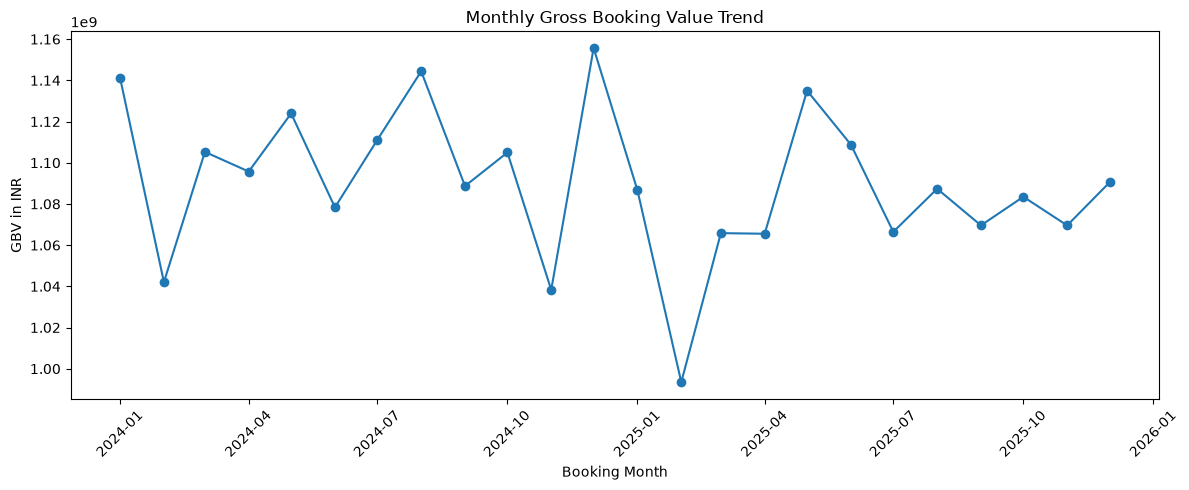

In [126]:
#lesson 3C create your first trend chart
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_trend["booking_month"],
    monthly_trend["total_gbv_inr"],
    marker="o"
)

plt.title("Monthly Gross Booking Value Trend")
plt.xlabel("Booking Month")
plt.ylabel("GBV in INR")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [127]:
#lesson 4 agent performance analysis in pandas
agent_performance = (
    bookings
    .groupby("agent_id")
    .agg(
        total_bookings=("booking_id", "count"),
        total_gbv_inr=("gross_booking_value_inr", "sum"),
        total_net_revenue_inr=("net_revenue_inr", "sum")
    )
    .reset_index()
)

agent_performance.head()

,agent_id,total_bookings,total_gbv_inr,total_net_revenue_inr
0,A00001,212,4.527757e+07,5.430291e+06
1,A00002,202,4.204394e+07,5.223622e+06
2,A00003,188,4.367688e+07,5.422234e+06
3,A00004,204,3.916711e+07,4.638386e+06
4,A00005,194,3.797639e+07,4.639664e+06


In [128]:
# find the top 10 agents by bookings
top_agents_bookings = (
    agent_performance
    .sort_values(
        "total_bookings",
        ascending=False
    )
    .head(10)
)

top_agents_bookings

,agent_id,total_bookings,total_gbv_inr,total_net_revenue_inr
144,A00145,249,5.252241e+07,6.539645e+06
184,A00185,244,5.261194e+07,6.618049e+06
143,A00144,235,5.320730e+07,6.681152e+06
90,A00091,235,4.809829e+07,5.840356e+06
84,A00085,234,4.665217e+07,5.954499e+06
30,A00031,227,4.423017e+07,5.406482e+06
70,A00071,227,4.414870e+07,5.222486e+06
274,A00275,227,4.990683e+07,6.528817e+06
217,A00218,227,5.159391e+07,6.172589e+06
125,A00126,227,4.890987e+07,5.851326e+06


In [129]:
# find the top agents by net revenue
top_agents_revenue = (
    agent_performance
    .sort_values(
        "total_net_revenue_inr",
        ascending=False
    )
    .head(10)
)

top_agents_revenue

,agent_id,total_bookings,total_gbv_inr,total_net_revenue_inr
237,A00238,203,5.317922e+07,6.823084e+06
151,A00152,212,5.363395e+07,6.735473e+06
109,A00110,220,5.331012e+07,6.696641e+06
143,A00144,235,5.320730e+07,6.681152e+06
184,A00185,244,5.261194e+07,6.618049e+06
116,A00117,226,5.327471e+07,6.592320e+06
275,A00276,188,5.101987e+07,6.575945e+06
12,A00013,219,5.348522e+07,6.554180e+06
144,A00145,249,5.252241e+07,6.539645e+06
68,A00069,201,4.966663e+07,6.532025e+06


In [130]:
print(
    "Active agents:",
    agent_performance["agent_id"].nunique()
)

Active agents: 7995


In [131]:
top_booking_agent = top_agents_bookings.iloc[0]

print("Top booking agent:", top_booking_agent["agent_id"])
print("Total bookings:", int(top_booking_agent["total_bookings"]))

top_revenue_agent = top_agents_revenue.iloc[0]

print("Top revenue agent:", top_revenue_agent["agent_id"])
print("Net revenue INR:", top_revenue_agent["total_net_revenue_inr"])

Top booking agent: A00145
Total bookings: 249
Top revenue agent: A00238
Net revenue INR: 6823083.5405


In [132]:
#lesson 4B agent cancellation rate analysis
bookings["is_cancelled_py"] = (
    bookings["booking_status"] == "Cancelled"
).astype(int)

In [133]:
agent_analysis = (
    bookings
    .groupby("agent_id")
    .agg(
        total_bookings=("booking_id", "count"),
        cancelled_bookings=("is_cancelled_py", "sum"),
        total_gbv_inr=("gross_booking_value_inr", "sum"),
        total_net_revenue_inr=("net_revenue_inr", "sum")
    )
    .reset_index()
)

In [134]:
#calculate cancellation rate
agent_analysis["cancellation_rate_pct"] = (
    agent_analysis["cancelled_bookings"]
    / agent_analysis["total_bookings"]
    * 100
)

In [135]:
high_cancel_agents = (
    agent_analysis[
        agent_analysis["total_bookings"] >= 20
    ]
    .sort_values(
        "cancellation_rate_pct",
        ascending=False
    )
    .head(10)
)

high_cancel_agents

,agent_id,total_bookings,cancelled_bookings,total_gbv_inr,total_net_revenue_inr,cancellation_rate_pct
9,A00010,183,90,3.781467e+07,4.922124e+06,49.180328
187,A00188,174,81,3.266848e+07,4.192719e+06,46.551724
24,A00025,187,85,4.418490e+07,6.029339e+06,45.454545
293,A00294,209,95,4.714778e+07,5.782977e+06,45.454545
269,A00270,205,93,4.410029e+07,5.557633e+06,45.365854
157,A00158,202,91,4.126518e+07,4.812626e+06,45.049505
289,A00290,215,95,4.589238e+07,6.109205e+06,44.186047
95,A00096,192,81,3.393823e+07,4.281814e+06,42.187500
53,A00054,197,83,4.031835e+07,5.049720e+06,42.131980
67,A00068,198,83,4.614921e+07,6.039738e+06,41.919192


In [136]:
#the higest cancellation agent clearly
top_cancel_agent = high_cancel_agents.iloc[0]

print("Agent:", top_cancel_agent["agent_id"])
print("Total bookings:", int(top_cancel_agent["total_bookings"]))
print("Cancelled bookings:", int(top_cancel_agent["cancelled_bookings"]))
print(
    "Cancellation rate:",
    round(top_cancel_agent["cancellation_rate_pct"], 2),
    "%"
)

Agent: A00010
Total bookings: 183
Cancelled bookings: 90
Cancellation rate: 49.18 %


In [137]:
top_cancel_agent = high_cancel_agents.iloc[0]

print("Agent:", top_cancel_agent["agent_id"])
print("Total bookings:", int(top_cancel_agent["total_bookings"]))
print("Cancelled bookings:", int(top_cancel_agent["cancelled_bookings"]))
print(
    "Cancellation rate:",
    round(top_cancel_agent["cancellation_rate_pct"], 2),
    "%"
)

Agent: A00010
Total bookings: 183
Cancelled bookings: 90
Cancellation rate: 49.18 %


In [138]:
#lesson 4C: destination analysis in pandas
#step 1 create destination summary
destination_analysis = (
    bookings
    .groupby("destination_id")
    .agg(
        total_bookings=("booking_id", "count"),
        cancelled_bookings=("is_cancelled_py", "sum"),
        total_gbv_inr=("gross_booking_value_inr", "sum"),
        total_net_revenue_inr=("net_revenue_inr", "sum")
    )
    .reset_index()
)

In [139]:
#step 2 calculate cancelation rate
destination_analysis["cancellation_rate_pct"] = (
    destination_analysis["cancelled_bookings"]
    / destination_analysis["total_bookings"]
    * 100
)

In [140]:
#step 3 find top destination by GBV
top_destination_gbv = (
    destination_analysis
    .sort_values("total_gbv_inr", ascending=False)
    .iloc[0]
)

print("Top destination by GBV:", top_destination_gbv["destination_id"])
print("Total bookings:", int(top_destination_gbv["total_bookings"]))
print("Total GBV INR:", top_destination_gbv["total_gbv_inr"])

Top destination by GBV: D0055
Total bookings: 730
Total GBV INR: 236051589.15


In [141]:
#step 4 find top destination by net revenue
top_destination_revenue = (
    destination_analysis
    .sort_values("total_net_revenue_inr", ascending=False)
    .iloc[0]
)

print(
    "Top destination by net revenue:",
    top_destination_revenue["destination_id"]
)

print(
    "Net revenue INR:",
    top_destination_revenue["total_net_revenue_inr"]
)

Top destination by net revenue: D0055
Net revenue INR: 29815399.44


In [142]:
#step 5 find high cancellation destinations
high_cancel_destinations = (
    destination_analysis[
        destination_analysis["total_bookings"] >= 100
    ]
    .sort_values(
        "cancellation_rate_pct",
        ascending=False
    )
    .head(10)
)

high_cancel_destinations

,destination_id,total_bookings,cancelled_bookings,total_gbv_inr,total_net_revenue_inr,cancellation_rate_pct
118,D0119,361,68,7.653031e+07,9.612701e+06,18.836565
97,D0098,317,53,8.419892e+07,1.106965e+07,16.719243
123,D0124,261,40,4.885990e+07,5.865591e+06,15.325670
236,D0237,399,61,9.665666e+07,1.165084e+07,15.288221
10,D0011,203,31,3.917808e+07,4.926573e+06,15.270936
274,D0275,323,49,5.720581e+07,7.051743e+06,15.170279
246,D0247,377,57,5.738114e+07,6.880334e+06,15.119363
27,D0028,246,37,6.709265e+07,8.212730e+06,15.040650
194,D0195,489,73,1.250746e+08,1.482255e+07,14.928425
130,D0131,333,49,5.988580e+07,7.755864e+06,14.714715


In [143]:
#to get top result
top_cancel_destination = high_cancel_destinations.iloc[0]

print("Destination:", top_cancel_destination["destination_id"])
print("Total bookings:", int(top_cancel_destination["total_bookings"]))
print("Cancelled bookings:", int(top_cancel_destination["cancelled_bookings"]))
print(
    "Cancellation rate:",
    round(top_cancel_destination["cancellation_rate_pct"], 2),
    "%"
)

Destination: D0119
Total bookings: 361
Cancelled bookings: 68
Cancellation rate: 18.84 %


In [144]:
#lesson 5 supplier profitability analysis
supplier_analysis = (
    bookings
    .groupby("supplier_id", dropna=False)
    .agg(
        total_bookings=("booking_id", "count"),
        total_gbv_inr=("gross_booking_value_inr", "sum"),
        total_supplier_cost_inr=("supplier_cost_inr", "sum"),
        total_net_revenue_inr=("net_revenue_inr", "sum")
    )
    .reset_index()
)

In [145]:
#now calculate gross margin
supplier_analysis["gross_margin_pct"] = (
    supplier_analysis["total_net_revenue_inr"]
    / supplier_analysis["total_gbv_inr"]
    * 100
)

In [146]:
#find the top supplier by GBV
top_supplier_gbv = (
    supplier_analysis
    .sort_values("total_gbv_inr", ascending=False)
    .iloc[0]
)

print("Top supplier by GBV:", top_supplier_gbv["supplier_id"])
print("Total GBV INR:", top_supplier_gbv["total_gbv_inr"])

Top supplier by GBV: S0079
Total GBV INR: 194698488.577255


In [147]:
#find the top supplier by net revenue
top_supplier_revenue = (
    supplier_analysis
    .sort_values("total_net_revenue_inr", ascending=False)
    .iloc[0]
)

print(
    "Top supplier by net revenue:",
    top_supplier_revenue["supplier_id"]
)

print(
    "Net revenue INR:",
    top_supplier_revenue["total_net_revenue_inr"]
)

Top supplier by net revenue: S0079
Net revenue INR: 24362907.356687


In [148]:
#find the strongest margin supplier among supplier with at least 100 bookings
strong_margin_suppliers = (
    supplier_analysis[
        supplier_analysis["total_bookings"] >= 100
    ]
    .sort_values("gross_margin_pct", ascending=False)
    .head(10)
)

strong_margin_suppliers

,supplier_id,total_bookings,total_gbv_inr,total_supplier_cost_inr,total_net_revenue_inr,gross_margin_pct
51,S0052,786,1.676549e+08,1.430580e+08,2.188560e+07,13.053964
49,S0050,756,1.760856e+08,1.506206e+08,2.297151e+07,13.045652
88,S0089,775,1.672927e+08,1.430204e+08,2.174182e+07,12.996277
95,S0096,758,1.701851e+08,1.455910e+08,2.207615e+07,12.971846
63,S0064,688,1.404759e+08,1.200781e+08,1.821726e+07,12.968247
132,S0133,754,1.806829e+08,1.546062e+08,2.336608e+07,12.932093
21,S0022,754,1.536726e+08,1.313157e+08,1.981061e+07,12.891439
158,S0159,733,1.647730e+08,1.412391e+08,2.121488e+07,12.875216
7,S0008,754,1.582317e+08,1.354024e+08,2.035229e+07,12.862334
54,S0055,802,1.724600e+08,1.478120e+08,2.217365e+07,12.857267


In [149]:
#weakest margin supplier
weak_margin_suppliers = (
    supplier_analysis[
        supplier_analysis["total_bookings"] >= 100
    ]
    .sort_values("gross_margin_pct", ascending=True)
    .head(10)
)

weak_margin_suppliers

,supplier_id,total_bookings,total_gbv_inr,total_supplier_cost_inr,total_net_revenue_inr,gross_margin_pct
142,S0143,709,1.650831e+08,1.428010e+08,1.926945e+07,11.672579
43,S0044,758,1.660369e+08,1.438808e+08,1.960035e+07,11.804815
34,S0035,729,1.643665e+08,1.422845e+08,1.943330e+07,11.823151
71,S0072,761,1.561642e+08,1.350776e+08,1.849223e+07,11.841532
112,S0113,731,1.618947e+08,1.401002e+08,1.917343e+07,11.843150
23,S0024,731,1.662659e+08,1.438353e+08,1.969426e+07,11.845042
0,S0001,723,1.686745e+08,1.461376e+08,2.011941e+07,11.927948
74,S0075,749,1.627643e+08,1.404516e+08,1.941665e+07,11.929309
121,S0122,730,1.496123e+08,1.291443e+08,1.785074e+07,11.931335
2,S0003,744,1.738046e+08,1.501032e+08,2.076706e+07,11.948511


In [150]:
#extract the margin leaders clearly
top_margin_supplier = strong_margin_suppliers.iloc[0]

print(
    "Highest margin supplier:",
    top_margin_supplier["supplier_id"]
)

print(
    "Highest margin %:",
    round(top_margin_supplier["gross_margin_pct"], 2)
)

Highest margin supplier: S0052
Highest margin %: 13.05


In [151]:
# the weakest margin
lowest_margin_supplier = weak_margin_suppliers.iloc[0]

print(
    "Lowest margin supplier:",
    lowest_margin_supplier["supplier_id"]
)

print(
    "Lowest margin %:",
    round(lowest_margin_supplier["gross_margin_pct"], 2)
)

Lowest margin supplier: S0143
Lowest margin %: 11.67


In [152]:
#lesson 5B: Hotel profitability analysis
#hotel summary
hotel_analysis = (
    bookings
    .groupby("hotel_id")
    .agg(
        total_bookings=("booking_id", "count"),
        total_gbv_inr=("gross_booking_value_inr", "sum"),
        total_net_revenue_inr=("net_revenue_inr", "sum")
    )
    .reset_index()
)

In [153]:
#calculate gross margin
hotel_analysis["gross_margin_pct"] = (
    hotel_analysis["total_net_revenue_inr"]
    / hotel_analysis["total_gbv_inr"]
    * 100
)

In [154]:
#find the top hotel by GBV
top_hotel_gbv = (
    hotel_analysis
    .sort_values("total_gbv_inr", ascending=False)
    .iloc[0]
)

print("Top hotel by GBV:", top_hotel_gbv["hotel_id"])
print("Total GBV INR:", top_hotel_gbv["total_gbv_inr"])

Top hotel by GBV: H00978
Total GBV INR: 25114212.21


In [155]:
#find the top hotel by net revenue
top_hotel_revenue = (
    hotel_analysis
    .sort_values("total_net_revenue_inr", ascending=False)
    .iloc[0]
)

print(
    "Top hotel by net revenue:",
    top_hotel_revenue["hotel_id"]
)

print(
    "Net revenue INR:",
    top_hotel_revenue["total_net_revenue_inr"]
)

Top hotel by net revenue: H00516
Net revenue INR: 2933066.45


In [156]:
#now compare margins only for hotels with at least 50 n=bookings
strong_margin_hotels = (
    hotel_analysis[
        hotel_analysis["total_bookings"] >= 50
    ]
    .sort_values("gross_margin_pct", ascending=False)
    .head(10)
)

weak_margin_hotels = (
    hotel_analysis[
        hotel_analysis["total_bookings"] >= 50
    ]
    .sort_values("gross_margin_pct", ascending=True)
    .head(10)
)

In [157]:
#extract the top and bottom rows
top_margin_hotel = strong_margin_hotels.iloc[0]
lowest_margin_hotel = weak_margin_hotels.iloc[0]

print("Highest margin hotel:", top_margin_hotel["hotel_id"])
print("Highest margin %:", round(top_margin_hotel["gross_margin_pct"], 2))

print("Lowest margin hotel:", lowest_margin_hotel["hotel_id"])
print("Lowest margin %:", round(lowest_margin_hotel["gross_margin_pct"], 2))

Highest margin hotel: H02897
Highest margin %: 15.42
Lowest margin hotel: H02297
Lowest margin %: 9.01


In [158]:
# hotel id 
print (
        "Top hotel by GBV : ",top_hotel_gbv["hotel_id"]
        )

Top hotel by GBV :  H00978


In [159]:
# lesson 6 cancellation & refund root cause analysis
#step 1 load cancellation data into pandas
cancel_query = """
SELECT *
FROM analytics.fact_cancellations_fx
WHERE is_fx_missing = 0;
"""

cancellations = pd.read_sql(cancel_query, engine)

In [160]:
#step 2 check cancellation reasons
cancellations["cancellation_reason"].value_counts()

cancellation_reason
Customer Change Of Plan    4823
Price Found Elsewhere      1996
Other                      1666
Supplier Rejection         1363
Visa Issue                 1233
Hotel Overbooking          1163
Payment Failure            1014
Duplicate Booking           714
Name: count, dtype: int64

In [161]:
#calculate percentage
cancellations["cancellation_reason"].value_counts(normalize = True)*100

cancellation_reason
Customer Change Of Plan    34.519038
Price Found Elsewhere      14.285714
Other                      11.923848
Supplier Rejection          9.755225
Visa Issue                  8.824792
Hotel Overbooking           8.323790
Payment Failure             7.257372
Duplicate Booking           5.110220
Name: proportion, dtype: float64

In [162]:
#step 3 build a cancellation summary
cancellation_summary = (
    cancellations
    .groupby("cancellation_reason")
    .agg(
        total_cancellations=("cancellation_id", "count"),
        total_refund_inr=("refund_amount_inr", "sum"),
        avg_refund_inr=("refund_amount_inr", "mean"),
        total_cancellation_fee_inr=("cancellation_fee_inr", "sum")
    )
    .reset_index()
)

cancellation_summary

,cancellation_reason,total_cancellations,total_refund_inr,avg_refund_inr,total_cancellation_fee_inr
0,Customer Change Of Plan,4823,1.021060e+09,211706.480139,3.632286e+07
1,Duplicate Booking,714,1.391514e+08,194889.947167,5.060703e+06
2,Hotel Overbooking,1163,2.402525e+08,206579.968920,8.501569e+06
3,Other,1666,3.457265e+08,207518.899405,1.256700e+07
4,Payment Failure,1014,2.155886e+08,212611.988908,7.242618e+06
5,Price Found Elsewhere,1996,4.250812e+08,212966.511163,1.415341e+07
6,Supplier Rejection,1363,2.889634e+08,212005.437391,9.508247e+06
7,Visa Issue,1233,2.517655e+08,204189.347054,9.061726e+06


In [163]:
#step 4 find the most common reason
top_cancel_reason = (
    cancellation_summary
    .sort_values(
        "total_cancellations",
        ascending=False
    )
    .iloc[0]
)

print(
    "Most common reason:",
    top_cancel_reason["cancellation_reason"]
)

print(
    "Cancellation count:",
    int(top_cancel_reason["total_cancellations"])
)

Most common reason: Customer Change Of Plan
Cancellation count: 4823


In [164]:
#step 5 find the reason with the higest refund impact
top_refund_reason = (
    cancellation_summary
    .sort_values(
        "total_refund_inr",
        ascending=False
    )
    .iloc[0]
)

print(
    "Highest total refund reason:",
    top_refund_reason["cancellation_reason"]
)

print(
    "Total refund INR:",
    top_refund_reason["total_refund_inr"]
)

Highest total refund reason: Customer Change Of Plan
Total refund INR: 1021060353.709772


In [165]:
#lesson 6B average refund & cancellation fee analysis
top_avg_refund_reason = (
    cancellation_summary
    .sort_values(
        "avg_refund_inr",
        ascending=False
    )
    .iloc[0]
)

print(
    "Highest average refund reason:",
    top_avg_refund_reason["cancellation_reason"]
)

print(
    "Average refund INR:",
    top_avg_refund_reason["avg_refund_inr"]
)

Highest average refund reason: Price Found Elsewhere
Average refund INR: 212966.5111628938


In [166]:
# find which reason generates the higest total cancellation fees
top_fee_reason = (
    cancellation_summary
    .sort_values(
        "total_cancellation_fee_inr",
        ascending=False
    )
    .iloc[0]
)

print(
    "Highest cancellation fee reason:",
    top_fee_reason["cancellation_reason"]
)

print(
    "Total cancellation fee INR:",
    top_fee_reason["total_cancellation_fee_inr"]
)

Highest cancellation fee reason: Customer Change Of Plan
Total cancellation fee INR: 36322858.615729


In [167]:
#calculate one more useful metric:
cancellation_summary["fee_to_refund_pct"] = (
    cancellation_summary["total_cancellation_fee_inr"]
    / cancellation_summary["total_refund_inr"]
    * 100
)

In [168]:
#inspect
cancellation_summary[
    [
        "cancellation_reason",
        "total_cancellations",
        "total_refund_inr",
        "avg_refund_inr",
        "total_cancellation_fee_inr",
        "fee_to_refund_pct"
    ]
].sort_values(
    "total_refund_inr",
    ascending=False
)

,cancellation_reason,total_cancellations,total_refund_inr,avg_refund_inr,total_cancellation_fee_inr,fee_to_refund_pct
0,Customer Change Of Plan,4823,1.021060e+09,211706.480139,3.632286e+07,3.557366
5,Price Found Elsewhere,1996,4.250812e+08,212966.511163,1.415341e+07,3.329578
3,Other,1666,3.457265e+08,207518.899405,1.256700e+07,3.634955
6,Supplier Rejection,1363,2.889634e+08,212005.437391,9.508247e+06,3.290468
7,Visa Issue,1233,2.517655e+08,204189.347054,9.061726e+06,3.599273
2,Hotel Overbooking,1163,2.402525e+08,206579.968920,8.501569e+06,3.538597
4,Payment Failure,1014,2.155886e+08,212611.988908,7.242618e+06,3.359463
1,Duplicate Booking,714,1.391514e+08,194889.947167,5.060703e+06,3.636832


In [169]:
#lesson 7 correlation & relationship analysis
#step 1 select numerical columns
correlation_data = bookings[
    [
        "rooms",
        "nights",
        "lead_days",
        "gross_booking_value_inr",
        "supplier_cost_inr",
        "discount_amount_inr",
        "net_revenue_inr"
    ]
]

In [170]:
#step2 calculate correlatons
correlation_matrix = correlation_data.corr()
correlation_matrix.round(2)

,rooms,nights,lead_days,gross_booking_value_inr,supplier_cost_inr,discount_amount_inr,net_revenue_inr
rooms,1.00,0.00,-0.01,0.46,0.46,0.26,0.41
nights,0.00,1.00,-0.00,0.58,0.58,0.33,0.51
lead_days,-0.01,-0.00,1.00,-0.00,-0.00,-0.00,-0.00
gross_booking_value_inr,0.46,0.58,-0.00,1.00,1.00,0.57,0.89
supplier_cost_inr,0.46,0.58,-0.00,1.00,1.00,0.57,0.86
discount_amount_inr,0.26,0.33,-0.00,0.57,0.57,1.00,0.38
net_revenue_inr,0.41,0.51,-0.00,0.89,0.86,0.38,1.00


In [171]:
#step 3 look specifically at GBV relationship
gbv_correlations = (
    correlation_matrix["gross_booking_value_inr"]
    .sort_values(ascending=False)
)

gbv_correlations

gross_booking_value_inr    1.000000
supplier_cost_inr          0.997559
net_revenue_inr            0.889448
nights                     0.579778
discount_amount_inr        0.570197
rooms                      0.460318
lead_days                 -0.004415
Name: gross_booking_value_inr, dtype: float64

In [172]:
#step 4 extract the key values 
print(
    "GBV vs Rooms:",
    round(
        correlation_matrix.loc[
            "gross_booking_value_inr",
            "rooms"
        ],
        3
    )
)

print(
    "GBV vs Nights:",
    round(
        correlation_matrix.loc[
            "gross_booking_value_inr",
            "nights"
        ],
        3
    )
)

print(
    "GBV vs Net Revenue:",
    round(
        correlation_matrix.loc[
            "gross_booking_value_inr",
            "net_revenue_inr"
        ],
        3
    )
)

print(
    "GBV vs Lead Days:",
    round(
        correlation_matrix.loc[
            "gross_booking_value_inr",
            "lead_days"
        ],
        3
    )
)

GBV vs Rooms: 0.46
GBV vs Nights: 0.58
GBV vs Net Revenue: 0.889
GBV vs Lead Days: -0.004


In [173]:
# lesson 8 final python insights + export for power BI
monthly_trend.to_csv(
    "monthly_trend_python.csv",
    index=False
)

agent_analysis.to_csv(
    "agent_analysis_python.csv",
    index=False
)

destination_analysis.to_csv(
    "destination_analysis_python.csv",
    index=False
)

supplier_analysis.to_csv(
    "supplier_analysis_python.csv",
    index=False
)

hotel_analysis.to_csv(
    "hotel_analysis_python.csv",
    index=False
)

cancellation_summary.to_csv(
    "cancellation_summary_python.csv",
    index=False
)

In [174]:
#then varify
print( " Pyhton analysis file exported successfully . ")

 Pyhton analysis file exported successfully . 
